# Import Modules and Classes

In [1]:
import networkx as nx

from poset import PoSet
from simplicial_complex import SimplicialComplex

# Testing PoSets

## Good PoSet

In [2]:
p = PoSet(S = {1,2,3}, R = {(1,1), (2,2), (3,3), (1,2), (2,3), (1,3)})

## Bad PoSets


In [3]:
%%script false --no-raise-error
p_not_reflexive = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (1,2), (2,1)},
)

In [4]:
%%script false --no-raise-error
p_not_antisymmetric = PoSet(S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,1)},
)

In [5]:
%%script false --no-raise-error
p_not_transative = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,3)},
)

In [6]:
list(p.S)
list(p.R)

[(1, 2), (1, 1), (2, 3), (3, 3), (2, 2), (1, 3)]

In [7]:


test_complex = SimplicialComplex([(1,2,3),(2,3,4),(3,5)])
print(len(test_complex.S))
print(len(test_complex.R))
print(test_complex.R) # shows unsorted
#test_complex.S

13
37
{(frozenset({2, 3}), frozenset({2, 3, 4})), (frozenset({2}), frozenset({1, 2})), (frozenset({4}), frozenset({3, 4})), (frozenset({1}), frozenset({1, 3})), (frozenset({2, 3}), frozenset({1, 2, 3})), (frozenset({1}), frozenset({1})), (frozenset({3}), frozenset({3})), (frozenset({1, 3}), frozenset({1, 3})), (frozenset({2}), frozenset({2, 3})), (frozenset({5}), frozenset({5})), (frozenset({1, 2, 3}), frozenset({1, 2, 3})), (frozenset({1, 2}), frozenset({1, 2, 3})), (frozenset({5}), frozenset({3, 5})), (frozenset({2, 3, 4}), frozenset({2, 3, 4})), (frozenset({1}), frozenset({1, 2, 3})), (frozenset({2, 4}), frozenset({2, 3, 4})), (frozenset({3}), frozenset({1, 3})), (frozenset({3}), frozenset({2, 3})), (frozenset({2}), frozenset({2, 4})), (frozenset({3}), frozenset({3, 5})), (frozenset({3, 4}), frozenset({2, 3, 4})), (frozenset({3, 5}), frozenset({3, 5})), (frozenset({1, 3}), frozenset({1, 2, 3})), (frozenset({2}), frozenset({2, 3, 4})), (frozenset({4}), frozenset({4})), (frozenset({3,

S = {{1}, {2}, {3}, {4}, {5}, {1, 2}, {1, 3}, {2, 3}, {2, 4}, {3, 4}, {3, 5}, {1, 2, 3}, {2, 3, 4}}
[1, 0, 2, 1, 1, 0, 1, 0, 1, 2, 1, 0, 0]
[0, 1, 2]
False


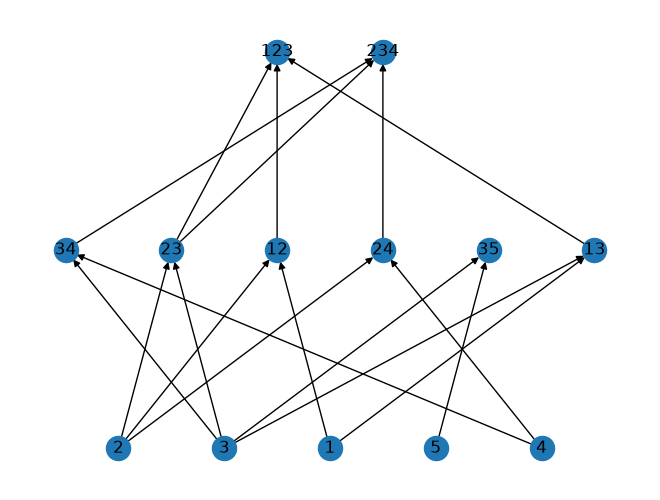

In [8]:
print(test_complex)

lengths = [len(f)-1 for f in test_complex.S]
print(lengths)

#length_positions = [e for e, i in enumerate(lengths) if i == 0]
#print(length_positions)

uni_lengths = list(range(max(lengths)+1))
print(uni_lengths)

print(test_complex.is_surface())

test_complex.draw_hasse()


In [9]:
[
    (test_complex._format_face(n), 
    list(map(
        test_complex._format_face, nx.descendants(test_complex.hasse_diagram(),n)
        ))
        )
    for n in test_complex.S]

G = test_complex.hasse_diagram()

tops = [n for n in G if G.out_degree(n) == 0]

[[p for p in G.predecessors(n) if G.out_degree(p) < 2] for n in tops]


test_complex.boundary_k()
#test_complex.facets()
#test_complex.n_simplices(1)



['{5}', '{1, 2}', '{1, 3}', '{3, 4}', '{2, 4}']

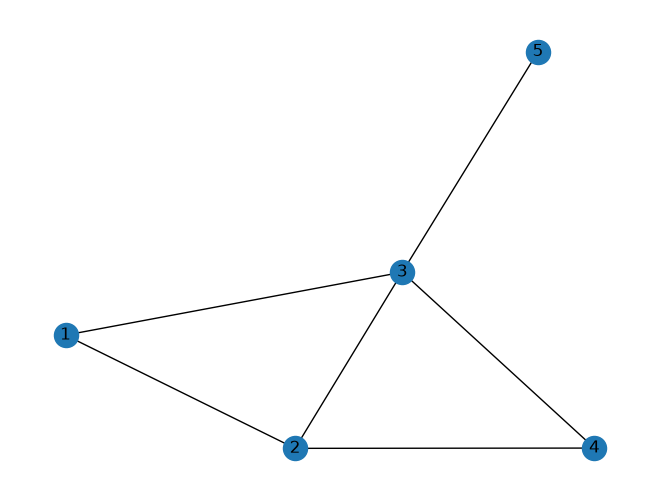

In [10]:
my_edges = test_complex.n_simplices(1)
g = nx.Graph()
g.add_edges_from(my_edges)
nx.draw(g, with_labels=True)

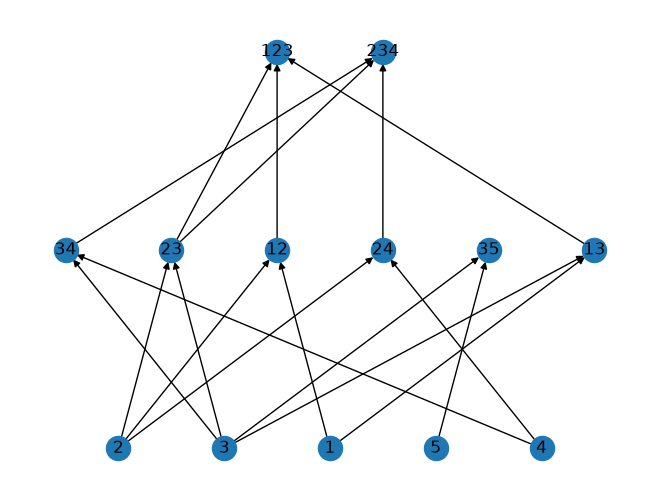

In [11]:
G = nx.DiGraph(test_complex.R)

G.remove_edges_from(list(nx.selfloop_edges(G)))

H = nx.transitive_reduction(G)

for n in H.nodes:
    H.nodes[n]["level"] = len(n)

pos = nx.multipartite_layout(H, subset_key="level", align="horizontal")

my_labels = {x: test_complex._node_label(x) for x in test_complex.S}

nx.draw(H, pos, labels=my_labels, with_labels=True)


True

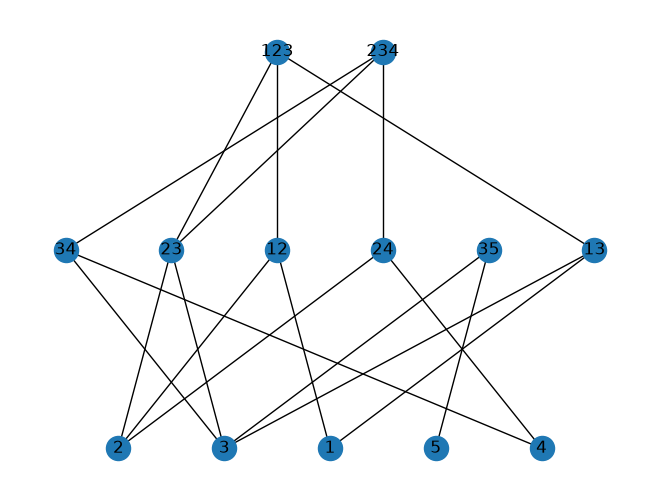

In [12]:
test_complex.dim()


H2 = H.to_undirected()
nx.draw(H2, pos=pos, labels =  my_labels, with_labels = True)

nx.is_connected(H2)

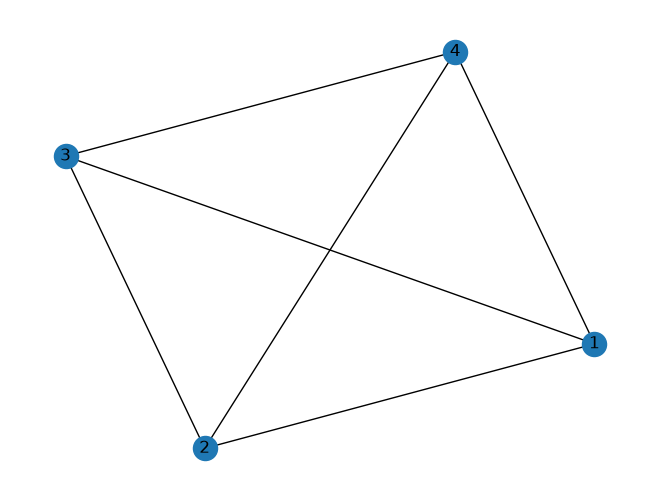

In [13]:
sphere = SimplicialComplex([(1,2,3),(1,2,4),(1,3,4), (2,3,4)])
s_edges = sphere.n_simplices(1)
s_graph = nx.Graph()
s_graph.add_edges_from(s_edges)
nx.draw(s_graph, with_labels=True)

In [14]:
s_hasse = sphere.hasse_diagram()

sphere.is_surface()

True

S = {{1}, {2}, {3}, {4}, {5}, {1, 2}, {1, 3}, {2, 3}, {2, 4}, {3, 4}, {3, 5}, {4, 5}, {1, 2, 3}, {2, 3, 4}, {3, 4, 5}}
(1, 2, 3)
(2, 3, 4)
(3, 4, 5)


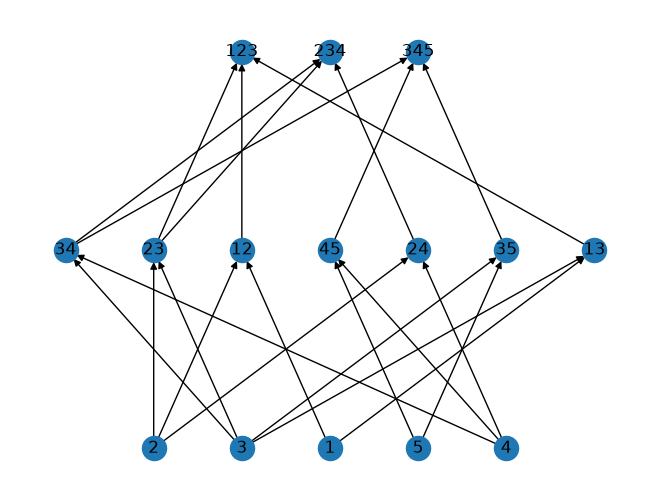

In [15]:
o_plex = SimplicialComplex([(1,2,3),(2,3,4),(3,4,5)])
print(o_plex)

#o_plex.complex_graph()

for n in o_plex.n_simplices(2):
    print(o_plex._orient_element(n))

o_hasse = o_plex.draw_hasse()

In [17]:
from itertools import permutations
x = tuple([1,2,3])
x
list(permutations(x))

[(1, 2, 3), (1, 3, 2), (2, 1, 3), (2, 3, 1), (3, 1, 2), (3, 2, 1)]